In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
import re
import joblib
import string

In [4]:
fake = pd.read_csv('Fake.csv')
true = pd.read_csv('True.csv')

In [5]:
fake.head()

,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [6]:
true.head()

,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [7]:
fake['class']=0
true['class']=1

In [8]:
data = pd.concat([fake, true], axis=0)

In [9]:
data.sample(10)

,title,text,subject,date,class
19693,"China, Singapore look to put difficulties behi...",BEIJING (Reuters) - China and Singapore on Tue...,worldnews,"September 19, 2017",1
15594,[VIDEO] WHAT JERRY SEINFELD HAS TO SAY ABOUT O...,"Kids Just Want To Use Words That s racist, th...",politics,"Jun 8, 2015",0
9391,Funding battle begins with House bill on regul...,WASHINGTON (Reuters) - The first shots in a po...,politicsNews,"May 25, 2016",1
15196,Islamist militants kill six soldiers in southe...,MANILA (Reuters) - Pro-Islamic State militants...,worldnews,"November 10, 2017",1
18738,POPULAR YOUTUBE PERSONALITY Goes Undercover Wi...,Tim Poole is citizen journalist who s done som...,left-news,"Apr 27, 2017",0
13307,WAPO DOES HONEST HIT-JOB ON HILLARY’S Failed J...,This is rich! Left-leaning Washington Post doe...,politics,"Aug 8, 2016",0
19786,"Nothing should change, says Britain in bid for...",LONDON (Reuters) - Britain proposed a new post...,worldnews,"September 18, 2017",1
20084,MELANIA PUNCHES BACK…HARD…After Leftist Public...,They had no basis for publishing their article...,left-news,"Aug 23, 2016",0
15967,Rare protest in junta-ruled Thailand after mou...,BANGKOK (Reuters) - Authorities in Thailand s ...,worldnews,"November 1, 2017",1
18838,"Facebook, Google, Twitter asked to testify on ...",WASHINGTON (Reuters) - Executives from Faceboo...,worldnews,"September 27, 2017",1


In [10]:
data = data.drop(['title','subject','date'],axis=1)

In [11]:
data.reset_index(inplace=True)

In [12]:
data.drop(['index'],axis=1,inplace=True)

In [13]:
data.sample(5)

,text,class
5504,Presidential elections are won by well-prepare...,0
28711,(Reuters) - Former U.S. president George W. Bu...,1
27005,(Reuters) - The U.S. Supreme Court on Tuesday ...,1
27875,BERLIN (Reuters) - German Chancellor Angela Me...,1
17767,Serial liar and 2020 Democrat presidential hop...,0


In [14]:
def clean_text(text):
    text = text.lower() 
    text = re.sub('\[.*?\]', '', text)
    text = re.sub('\\W', ' ', text)
    text = re.sub('http\S+|www\S+|https\S+', '', text)
    text = re.sub('<.*?>+', '', text)
    text = re.sub('[%s]' % re.escape(string.punctuation), '', text)
    text = re.sub('\n', '', text)
    text = re.sub('\w*\d\w*', '', text)
    return text

<>:3: SyntaxWarning: invalid escape sequence '\['
<>:5: SyntaxWarning: invalid escape sequence '\S'
<>:9: SyntaxWarning: invalid escape sequence '\w'
<>:3: SyntaxWarning: invalid escape sequence '\['
<>:5: SyntaxWarning: invalid escape sequence '\S'
<>:9: SyntaxWarning: invalid escape sequence '\w'
C:\Users\kavinkumar\AppData\Local\Temp\ipykernel_24828\988964414.py:3: SyntaxWarning: invalid escape sequence '\['
  text = re.sub('\[.*?\]', '', text)
C:\Users\kavinkumar\AppData\Local\Temp\ipykernel_24828\988964414.py:5: SyntaxWarning: invalid escape sequence '\S'
  text = re.sub('http\S+|www\S+|https\S+', '', text)
C:\Users\kavinkumar\AppData\Local\Temp\ipykernel_24828\988964414.py:9: SyntaxWarning: invalid escape sequence '\w'
  text = re.sub('\w*\d\w*', '', text)


In [15]:
data['text'] = data['text'].apply(clean_text)

In [16]:
X = data['text']
y = data['class']

xtrain, xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, random_state=42)   

In [17]:
# Ensure text data are strings (avoid sparse-matrix/bytes issues)
xtrain = xtrain.astype(str)
xtest = xtest.astype(str)

vectorizer = TfidfVectorizer()
xv_train = vectorizer.fit_transform(xtrain)
xv_test = vectorizer.transform(xtest)

# Save the vectorizer for later use
joblib.dump(vectorizer, 'tfidf_vectorizer.pkl')
print('Vectorizer fitted and saved to tfidf_vectorizer.pkl')

Vectorizer fitted and saved to tfidf_vectorizer.pkl


In [18]:
from sklearn.metrics import accuracy_score

# Train logistic regression (increase max_iter to ensure convergence)
lr = LogisticRegression(max_iter=1000)
lr.fit(xv_train, ytrain)

# Evaluate
pred = lr.predict(xv_test)
print('Classification report:')
print(classification_report(ytest, pred))
print('Accuracy:', accuracy_score(ytest, pred))

# Save the trained model
joblib.dump(lr, 'logistic_model.pkl')
print('Trained model saved to logistic_model.pkl')

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      4733
           1       0.98      0.99      0.98      4247

    accuracy                           0.99      8980
   macro avg       0.99      0.99      0.99      8980
weighted avg       0.99      0.99      0.99      8980

Accuracy: 0.9856347438752784
Trained model saved to logistic_model.pkl


In [19]:
# Metrics prep: probabilities, confusion matrix, and distributions
import os
import numpy as np
import pandas as pd
import joblib
import re
import string
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve

# Helper: cleaning (aligned with earlier cell)
def clean_text(text):
    text = text.lower()
    text = re.sub(r'\[.*?\]', '', text)
    text = re.sub(r'\W', ' ', text)
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)
    text = re.sub(r'<.*?>+', '', text)
    text = re.sub('[%s]' % re.escape(string.punctuation), '', text)
    text = re.sub(r'\n', '', text)
    text = re.sub(r'\w*\d\w*', '', text)
    return text

# Try to use existing variables from training; otherwise, rebuild minimal test set and load artifacts
try:
    lr  # noqa: F821  # type: ignore
    vectorizer  # noqa: F821  # type: ignore
    xv_test  # noqa: F821  # type: ignore
    ytest  # noqa: F821  # type: ignore
except NameError:
    # Load artifacts
    VECTORIZER_PATH = os.path.join(os.getcwd(), 'tfidf_vectorizer.pkl')
    MODEL_PATH = os.path.join(os.getcwd(), 'logistic_model.pkl')
    if not (os.path.exists(VECTORIZER_PATH) and os.path.exists(MODEL_PATH)):
        raise RuntimeError('Artifacts not found. Re-run training cells to generate plots.')
    vectorizer = joblib.load(VECTORIZER_PATH)
    lr = joblib.load(MODEL_PATH)

    # Load and prepare data (use same steps as training)
    fake_path = 'Fake.csv'
    true_path = 'True.csv'
    if not os.path.exists(fake_path):
        fake_path = os.path.join('DataSet', 'Fake.csv')
    if not os.path.exists(true_path):
        true_path = os.path.join('DataSet', 'True.csv')

    fake = pd.read_csv(fake_path)
    true = pd.read_csv(true_path)
    fake['class'] = 0
    true['class'] = 1
    data = pd.concat([fake, true], axis=0)
    data = data.drop(['title', 'subject', 'date'], axis=1)
    data.reset_index(inplace=True)
    data.drop(['index'], axis=1, inplace=True)
    data['text'] = data['text'].apply(clean_text)

    X = data['text']
    y = data['class']
    xtrain, xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, random_state=42)
    xtest = xtest.astype(str)
    xv_test = vectorizer.transform(xtest)

# Compute predictions and probabilities on test set
pred = lr.predict(xv_test)
pred_proba = lr.predict_proba(xv_test)[:, 1]  # probability of class 1 (real)

# Confusion matrix
cm = confusion_matrix(ytest, pred)
cm

array([[4660,   73],
       [  56, 4191]])

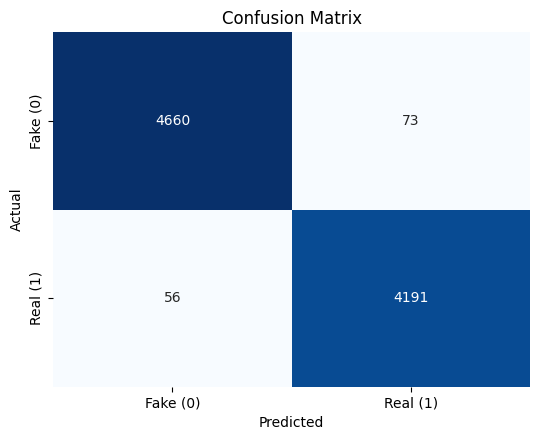

In [20]:
# Plot Confusion Matrix
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Fake (0)', 'Real (1)'],
            yticklabels=['Fake (0)', 'Real (1)'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

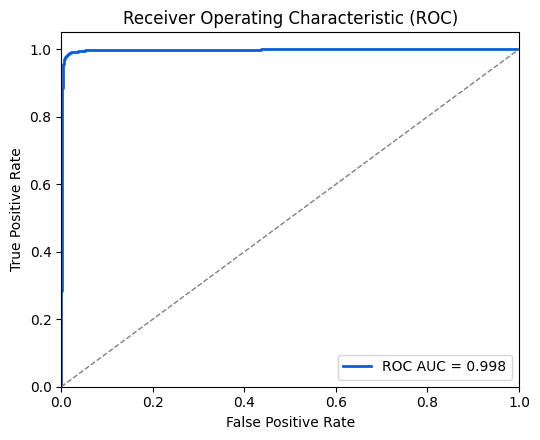

In [21]:
# ROC Curve
fpr, tpr, _ = roc_curve(ytest, pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(5.5, 4.5))
plt.plot(fpr, tpr, color='#0b5ed7', lw=2, label=f'ROC AUC = {roc_auc:.3f}')
plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

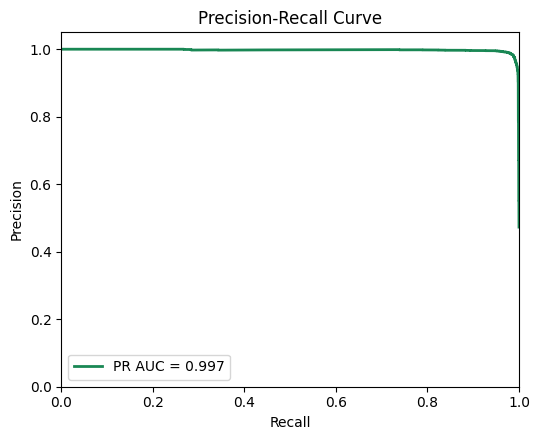

In [22]:
# Precision-Recall Curve
prec, rec, _ = precision_recall_curve(ytest, pred_proba)
pr_auc = auc(rec, prec)

plt.figure(figsize=(5.5, 4.5))
plt.plot(rec, prec, color='#198754', lw=2, label=f'PR AUC = {pr_auc:.3f}')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

C:\Users\kavinkumar\AppData\Local\Temp\ipykernel_24828\3012756459.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='weight', y='feature', data=top_pos.sort_values('weight'), ax=axes[0], palette='Greens')
C:\Users\kavinkumar\AppData\Local\Temp\ipykernel_24828\3012756459.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='weight', y='feature', data=top_neg.sort_values('weight'), ax=axes[1], palette='Reds')


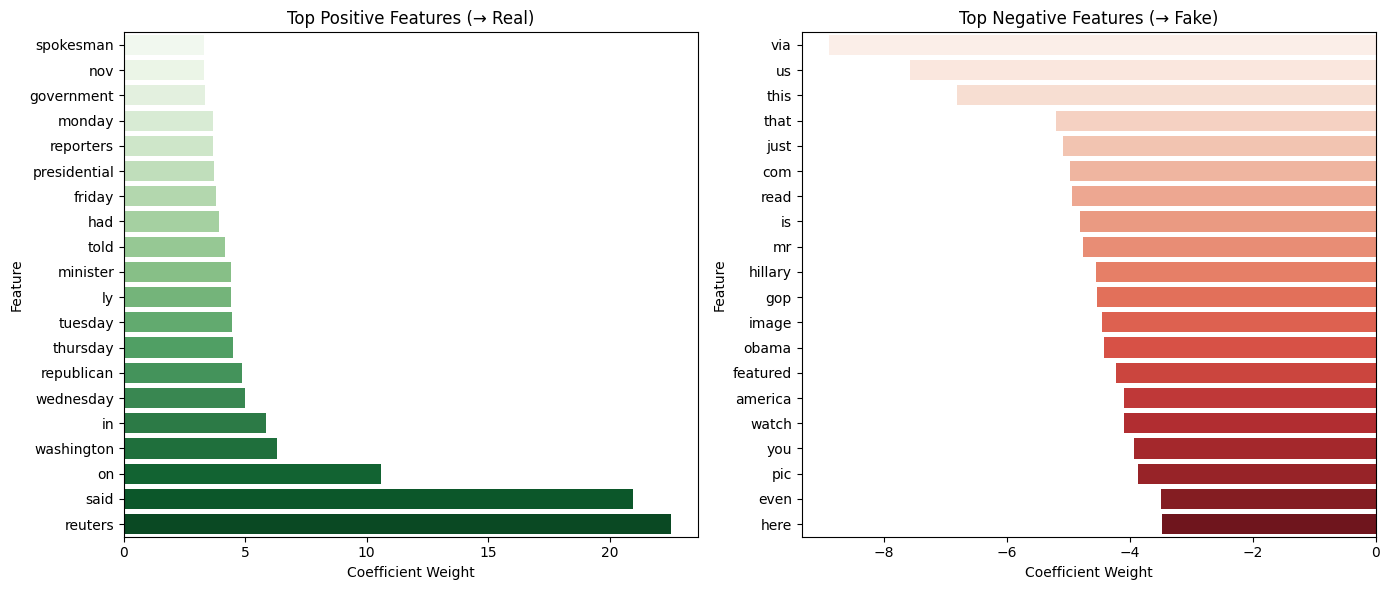

In [23]:
# Top features (most indicative words)
import pandas as pd
feature_names = vectorizer.get_feature_names_out()
coefs = lr.coef_[0]

top_n = 20
top_pos_idx = np.argsort(coefs)[-top_n:][::-1]
top_neg_idx = np.argsort(coefs)[:top_n]

top_pos = pd.DataFrame({
    'feature': feature_names[top_pos_idx],
    'weight': coefs[top_pos_idx]
})
top_neg = pd.DataFrame({
    'feature': feature_names[top_neg_idx],
    'weight': coefs[top_neg_idx]
})

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=False)
sns.barplot(x='weight', y='feature', data=top_pos.sort_values('weight'), ax=axes[0], palette='Greens')
axes[0].set_title('Top Positive Features (→ Real)')
axes[0].set_xlabel('Coefficient Weight')
axes[0].set_ylabel('Feature')

sns.barplot(x='weight', y='feature', data=top_neg.sort_values('weight'), ax=axes[1], palette='Reds')
axes[1].set_title('Top Negative Features (→ Fake)')
axes[1].set_xlabel('Coefficient Weight')
axes[1].set_ylabel('Feature')
plt.tight_layout()
plt.show()